# Sobol — Stovepipe (fac=0, amb=0)

Sensitivity analysis on T1 mortality.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/20260605_212356_scenario_2btg_pooling_limit_baseline_stove/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
from SALib.analyze import sobol as sobol_analyze

sub = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
print(f"Policy: Stovepipe (fac=0, amb=0), {len(sub)} runs")

OUTCOME = "death_rate_T1_BCAS"

problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES,
    "bounds": [[10, 20], [0.01, 0.07], [1, 6], [1, 60]],
}

N = len(sub) // (2 * problem["num_vars"] + 2)
print(f"Inferred N = {N}")
print(f"Expected Saltelli rows: {N * (2 * problem['num_vars'] + 2)}")
print(f"Actual rows: {len(sub)}")


Loaded 40960 runs


Policy: Stovepipe (fac=0, amb=0), 10240 runs
Inferred N = 1024
Expected Saltelli rows: 10240
Actual rows: 10240


## S1 and ST


                          ST   ST_conf
ccp_r1_same_bn_min  0.759935  0.067702
bcas_rate           0.029995  0.007770
waves_per_day       0.078618  0.015689
wave_duration_min   0.504163  0.057214
                          S1   S1_conf
ccp_r1_same_bn_min  0.414524  0.072949
bcas_rate          -0.003908  0.014646
waves_per_day      -0.002384  0.025379
wave_duration_min   0.211884  0.068657
                                               S2   S2_conf
(ccp_r1_same_bn_min, bcas_rate)          0.021196  0.086915
(ccp_r1_same_bn_min, waves_per_day)      0.024791  0.087350
(ccp_r1_same_bn_min, wave_duration_min)  0.246193  0.106081
(bcas_rate, waves_per_day)               0.014399  0.019570
(bcas_rate, wave_duration_min)           0.006905  0.018316
(waves_per_day, wave_duration_min)       0.026821  0.031634


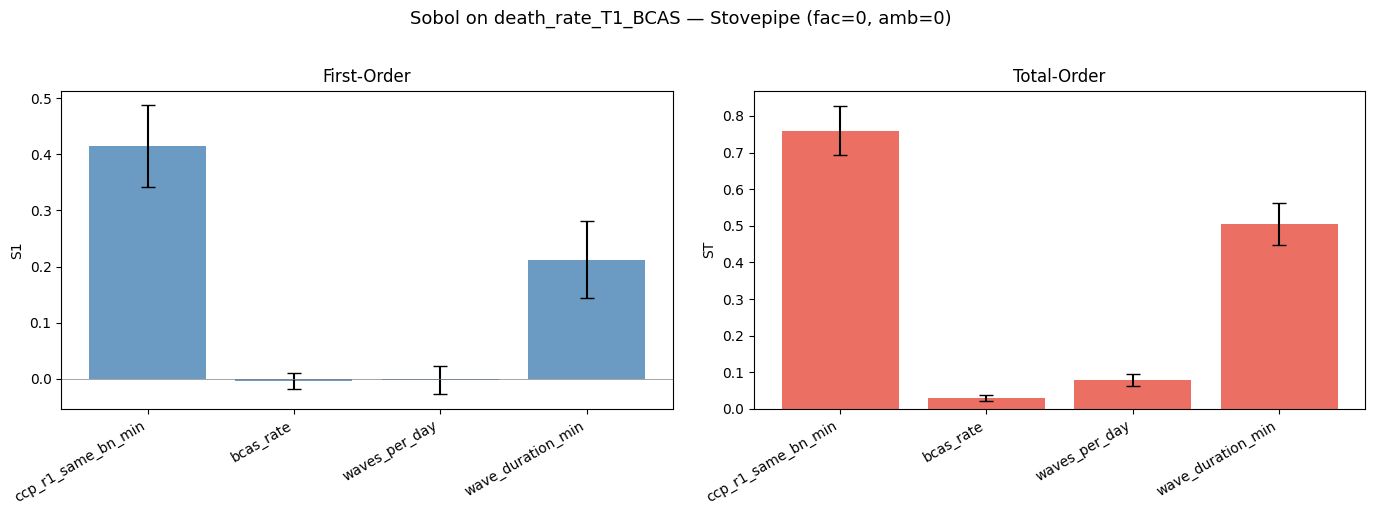

                        S1  S1_conf     ST  ST_conf
ccp_r1_same_bn_min  0.4145   0.0729 0.7599   0.0677
bcas_rate          -0.0039   0.0146 0.0300   0.0078
waves_per_day      -0.0024   0.0254 0.0786   0.0157
wave_duration_min   0.2119   0.0687 0.5042   0.0572


In [2]:
Si = sobol_analyze.analyze(problem, sub[OUTCOME].values, calc_second_order=True, print_to_console=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = np.arange(len(UNCERTAINTIES))

axes[0].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=5, color="steelblue", alpha=0.8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[0].set_ylabel("S1")
axes[0].set_title("First-Order")
axes[0].axhline(0, color="grey", linewidth=0.5)

axes[1].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=5, color="#e74c3c", alpha=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
axes[1].set_ylabel("ST")
axes[1].set_title("Total-Order")
axes[1].axhline(0, color="grey", linewidth=0.5)

fig.suptitle("Sobol on death_rate_T1_BCAS — Stovepipe (fac=0, amb=0)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"], "ST": Si["ST"], "ST_conf": Si["ST_conf"]}, index=UNCERTAINTIES).to_string(float_format="%.4f"))


## S2 — Pairwise Interactions


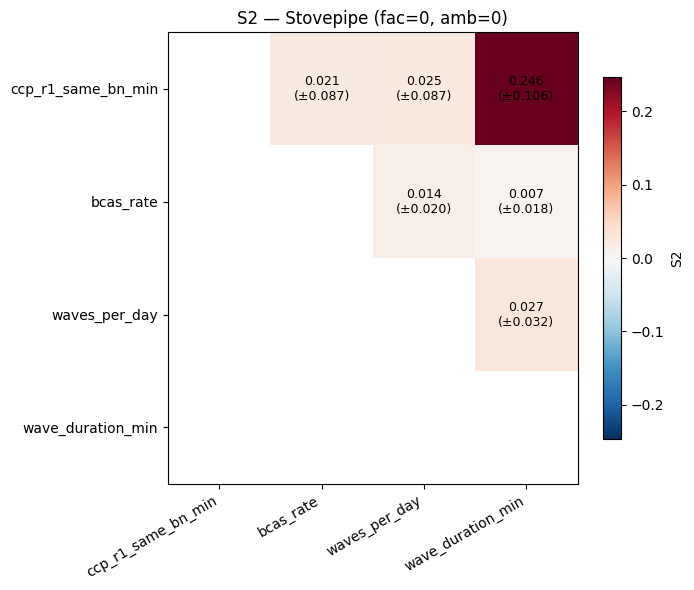

In [3]:
S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES, columns=UNCERTAINTIES)
S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES, columns=UNCERTAINTIES)

fig, ax = plt.subplots(figsize=(7, 6))
mask = np.tril(np.ones_like(S2, dtype=bool), k=0)
s2_masked = S2.where(~mask)
vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
im = ax.imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
ax.set_xticks(range(len(UNCERTAINTIES)))
ax.set_xticklabels(UNCERTAINTIES, rotation=30, ha="right")
ax.set_yticks(range(len(UNCERTAINTIES)))
ax.set_yticklabels(UNCERTAINTIES)
ax.set_title("S2 — Stovepipe (fac=0, amb=0)")
for i in range(len(UNCERTAINTIES)):
    for j in range(len(UNCERTAINTIES)):
        if not mask[i, j]:
            v = S2.iloc[i, j]
            c = S2_conf.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.3f}\n(±{c:.3f})", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8, label="S2")
plt.tight_layout()
plt.show()
